# Dataset B — Final PlainMLP

## tl;dr

Dashboard này chỉ đọc frozen evidence của `plain_mlp_final_15f_20261004_03`.
Run sử dụng final 15-feature contract, năm fold Train-only, full-Train refit,
Validation threshold `0.543`, Test/RQ1 evaluation và 1.000 locked-bootstrap
replicates. Notebook không fit, inference, chọn lại threshold, đổi metric hoặc
tái tạo bootstrap indices.


## Context & Methods

Nguồn hiển thị là sáu reporting files đã qua PMLP-X08/X09 final review. Bundle
được đọc từ `artifacts/dataset_b/plain_mlp/final/<run_id>` và phải có marker
`FROZEN`. Mọi bảng và chart bên dưới là presentation của evidence đã lưu.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'config/dataset_b/model_protocol_v1.yaml').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Cannot locate the Dataset B project root.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset_b.reporting.model_reporting import validate_reporting_directory

RUN_ID = 'plain_mlp_final_15f_20261004_03'
RUN_DIR = PROJECT_ROOT / 'artifacts/dataset_b/plain_mlp/final' / RUN_ID
REPORTING_DIR = RUN_DIR / 'reporting'
assert (RUN_DIR / 'FROZEN').is_file(), 'PlainMLP final bundle is not frozen.'

summary = validate_reporting_directory(REPORTING_DIR)
assert summary['model_key'] == 'plain_mlp'
assert summary['reporting_key'] == 'plain_mlp'
assert summary['run_id'] == RUN_ID
assert summary['reporting_status'] == 'COMPLETE'

cv = pd.read_csv(REPORTING_DIR / 'cv_fold_metrics.csv')
metrics = pd.read_csv(REPORTING_DIR / 'rq1_metrics_long.csv')
confusion = pd.read_csv(REPORTING_DIR / 'confusion_matrix.csv')
calibration = pd.read_csv(REPORTING_DIR / 'calibration_curve.csv')

display(Markdown(
    f"**Frozen final evidence: PASS** — run `{RUN_ID}`; "
    f"{summary['data_boundaries']['train_rows']:,} Train, "
    f"{summary['data_boundaries']['validation_rows']:,} Validation, "
    f"{summary['data_boundaries']['test_rows']:,} Test rows."
))


**Frozen final evidence: PASS** — run `plain_mlp_final_15f_20261004_03`; 205,310 Train, 43,995 Validation, 43,996 Test rows.

## Data & lineage


In [2]:
lineage = pd.DataFrame([
    ('Run ID', summary['run_id']),
    ('Reporting key', summary['reporting_key']),
    ('Feature version', summary['feature_version']),
    ('Split version', summary['split_version']),
    ('Preprocessing version', summary['preprocessing_version']),
    ('Raw / semantic / model inputs', '15 / 19 / 62'),
    ('Frozen marker', 'PRESENT'),
], columns=['Field', 'Value'])
display(lineage.style.hide(axis='index'))

stages = pd.DataFrame(
    [(name, status) for name, status in summary['stages'].items()],
    columns=['Stage', 'Status'],
)
display(stages.style.hide(axis='index'))


Field,Value
Run ID,plain_mlp_final_15f_20261004_03
Reporting key,plain_mlp
Feature version,feature_set_v1
Split version,split_v1
Preprocessing version,dataset_b_neural_preprocessing_v1
Raw / semantic / model inputs,15 / 19 / 62
Frozen marker,PRESENT


Stage,Status
cuda_smoke,PASS
final_review,PASS
full_train_fit,PASS
preprocessing,PASS
test_evaluation,PASS
train_only_cv,PASS
train_only_pilot,PASS
validation_threshold,PASS


## Train-only CV/OOF


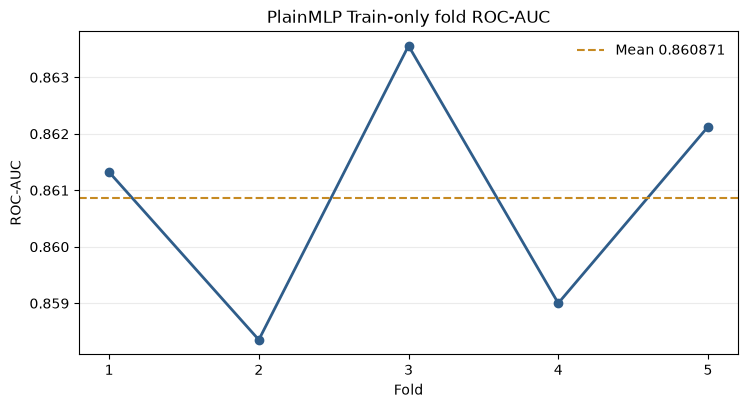

CV evidence,Value
Fold count,5.0000000000
Mean fold ROC-AUC,0.8608714166
Std fold ROC-AUC,0.0019406031
OOF ROC-AUC,0.8605005847
OOF rows,"205,310.0000000000"


In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(cv['fold'], cv['roc_auc'], marker='o', linewidth=2, color='#2F5D8A')
ax.axhline(summary['cv']['mean_roc_auc'], linestyle='--', color='#C68A22',
           label=f"Mean {summary['cv']['mean_roc_auc']:.6f}")
ax.set(title='PlainMLP Train-only fold ROC-AUC', xlabel='Fold', ylabel='ROC-AUC')
ax.set_xticks(cv['fold'])
ax.grid(axis='y', alpha=.25)
ax.legend(frameon=False)
plt.show()

cv_summary = pd.DataFrame([
    ('Fold count', summary['cv']['fold_count']),
    ('Mean fold ROC-AUC', summary['cv']['mean_roc_auc']),
    ('Std fold ROC-AUC', summary['cv']['std_roc_auc']),
    ('OOF ROC-AUC', summary['cv']['oof_roc_auc']),
    ('OOF rows', summary['cv']['oof_rows']),
], columns=['CV evidence', 'Value'])
display(cv_summary.style.hide(axis='index').format({'Value': lambda x: f'{x:,.10f}' if isinstance(x, float) else f'{x:,}'}))


## Validation threshold và Test/RQ1


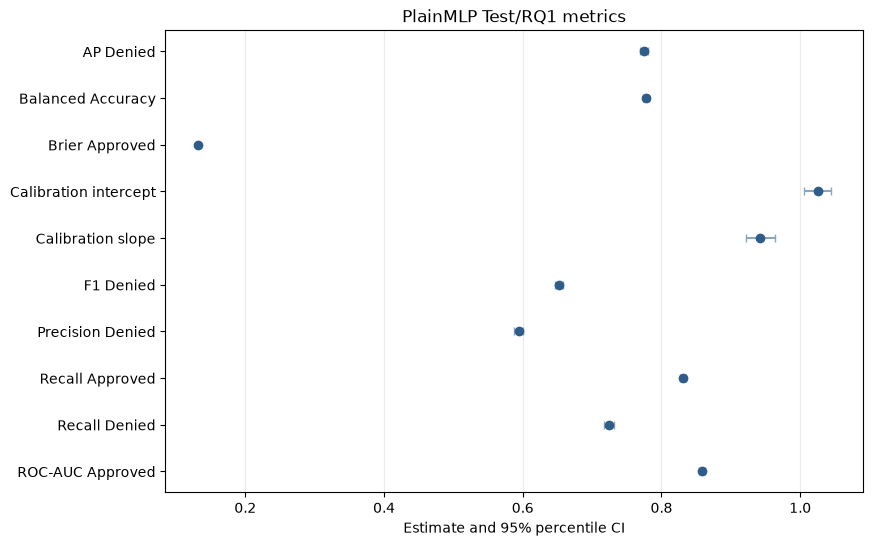

metric,estimate,ci_low,ci_high,valid_replicates
average_precision_denied,0.775313,0.769312,0.781168,1000
balanced_accuracy,0.777839,0.773175,0.782068,1000
brier_score_approved,0.132112,0.130510,0.133816,1000
calibration_intercept,1.025936,1.005994,1.044666,1000
calibration_slope,0.942358,0.921471,0.963799,1000
f1_denied,0.652726,0.646609,0.658245,1000
precision_denied,0.593929,0.587035,0.599856,1000
recall_approved,0.831236,0.826938,0.835015,1000
recall_denied,0.724443,0.716573,0.732139,1000
roc_auc_approved,0.858790,0.854385,0.862776,1000


In [4]:
metric_labels = {
    'roc_auc_approved': 'ROC-AUC Approved',
    'average_precision_denied': 'AP Denied',
    'precision_denied': 'Precision Denied',
    'recall_denied': 'Recall Denied',
    'f1_denied': 'F1 Denied',
    'recall_approved': 'Recall Approved',
    'balanced_accuracy': 'Balanced Accuracy',
    'brier_score_approved': 'Brier Approved',
    'calibration_intercept': 'Calibration intercept',
    'calibration_slope': 'Calibration slope',
}
plot_data = metrics.copy()
plot_data['label'] = plot_data['metric'].map(metric_labels)
plot_data = plot_data.iloc[::-1].reset_index(drop=True)
y = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(
    plot_data['estimate'], y,
    xerr=[plot_data['estimate'] - plot_data['ci_low'], plot_data['ci_high'] - plot_data['estimate']],
    fmt='o', color='#2F5D8A', ecolor='#8AA6BF', capsize=3,
)
ax.set_yticks(y, plot_data['label'])
ax.set_xlabel('Estimate and 95% percentile CI')
ax.set_title('PlainMLP Test/RQ1 metrics')
ax.grid(axis='x', alpha=.25)
plt.show()

display(metrics[['metric', 'estimate', 'ci_low', 'ci_high', 'valid_replicates']]
        .style.hide(axis='index').format({'estimate': '{:.6f}', 'ci_low': '{:.6f}', 'ci_high': '{:.6f}'}))


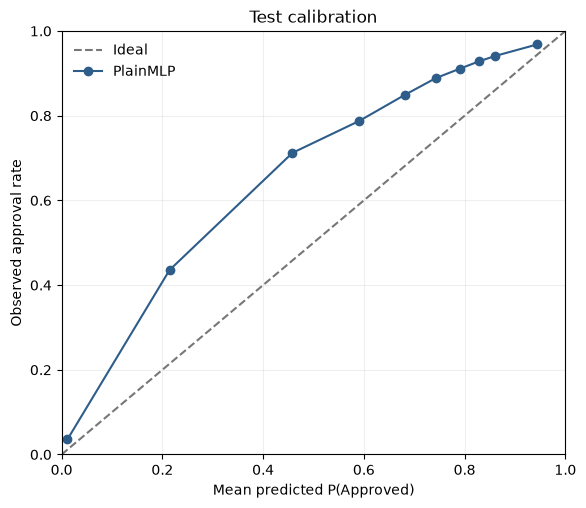

**Frozen Validation threshold:** `0.543`

predicted_class,approved,denied
actual_class,,
approved,"27,277","5,538"
denied,"3,081","8,100"


In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 1], [0, 1], linestyle='--', color='#777777', label='Ideal')
ax.plot(calibration['mean_p_approved'], calibration['observed_approval_rate'],
        marker='o', color='#2F5D8A', label='PlainMLP')
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted P(Approved)',
       ylabel='Observed approval rate', title='Test calibration')
ax.grid(alpha=.2)
ax.legend(frameon=False)
plt.show()

confusion_table = confusion.pivot(index='actual_class', columns='predicted_class', values='count')
display(Markdown(f"**Frozen Validation threshold:** `{summary['selected_threshold']:.3f}`"))
display(confusion_table.style.format('{:,}'))


## Execution boundary


In [6]:
boundary = pd.DataFrame([
    ('Reporting fit calls', summary['execution']['fit_calls']),
    ('Reporting predict_proba calls', summary['execution']['predict_proba_calls']),
    ('Threshold changed during reporting', summary['execution']['threshold_changed']),
    ('Bootstrap regenerated during reporting', summary['execution']['bootstrap_regenerated']),
    ('Bootstrap replicates', int(metrics['valid_replicates'].max())),
], columns=['Boundary', 'Recorded value'])
display(boundary.style.hide(axis='index'))
assert summary['execution'] == {
    'fit_calls': 0,
    'predict_proba_calls': 0,
    'threshold_changed': False,
    'bootstrap_regenerated': False,
}
display(Markdown(
    '**Conclusion:** final PlainMLP reporting evidence is frozen and COMPLETE. '
    'Notebook 07 may consume this reporting package, while six-model comparison '
    'remains gated until all required model summaries are available.'
))


Boundary,Recorded value
Reporting fit calls,0
Reporting predict_proba calls,0
Threshold changed during reporting,False
Bootstrap regenerated during reporting,False
Bootstrap replicates,1000


**Conclusion:** final PlainMLP reporting evidence is frozen and COMPLETE. Notebook 07 may consume this reporting package, while six-model comparison remains gated until all required model summaries are available.